Original RGM dataset:
    Rubber_Content (%)  Confining_Pressure (kPa)  Peak_Deviator_Stress (kPa)
0                    0                        10                         155
1                   10                        10                         135
2                   20                        10                         115
3                   30                        10                          82
4                   40                        10                          75
5                    0                        40                         350
6                   10                        40                         295
7                   20                        40                         255
8                   30                        40                         250
9                   40                        40                         220
10                   0                        70                         525
11                  10                        70      

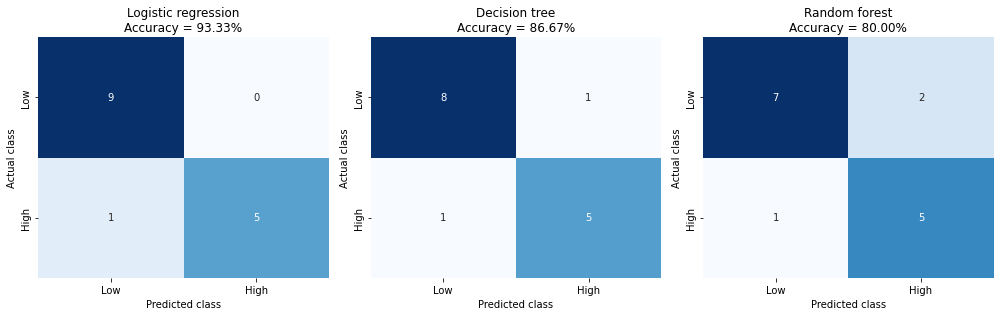


Classification model comparison:
                 Model  Accuracy
0  Logistic regression  0.933333
1        Decision tree  0.866667
2        Random forest  0.800000

Classification analysis completed successfully.


In [1]:

# ============================================
# RGM mechanical response classification
# PYTHON206 practical exercise
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

# 1. Approximate RGM experimental data
# Digitised from published figures

data = {
    'Rubber_Content (%)': [0, 10, 20, 30, 40] * 3,
    'Confining_Pressure (kPa)': [10]*5 + [40]*5 + [70]*5,
    'Peak_Deviator_Stress (kPa)': [
        155, 135, 115, 82, 75,
        350, 295, 255, 250, 220,
        525, 410, 355, 350, 315
    ]
}

df = pd.DataFrame(data)

print("Original RGM dataset:")
print(df)

# 2. Define classification labels
# Demonstration threshold: 300 kPa
# 0 = Low stress, 1 = High stress

df['Stress_Class'] = (
    df['Peak_Deviator_Stress (kPa)'] >= 300
).astype(int)

# 3. Select input features and target
X = df[[
    'Rubber_Content (%)',
    'Confining_Pressure (kPa)'
]]

y = df['Stress_Class']

# 4. Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 5. Define classification models
models = {
    'Logistic regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    'Decision tree': DecisionTreeClassifier(
        max_depth=2,
        random_state=42
    ),

    'Random forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=3,
        random_state=42
    )
}

# 6. Train and evaluate classification models
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

results = []

for ax, (name, model) in zip(axes, models.items()):

    # Cross-validated predictions
    y_pred = cross_val_predict(
        model, X, y, cv=cv
    )

    # Calculate classification accuracy
    accuracy = accuracy_score(y, y_pred)

    results.append({
        'Model': name,
        'Accuracy': accuracy
    })

    print(f"\n{name}")
    print(classification_report(
        y, y_pred,
        labels=[0, 1],
        target_names=['Low', 'High'],
        zero_division=0
    ))

    # Generate confusion matrix
    cm = confusion_matrix(
        y, y_pred,
        labels=[0, 1]
    )

    # Plot confusion matrix heatmap
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=['Low', 'High'],
        yticklabels=['Low', 'High'],
        ax=ax
    )

    ax.set_title(
        f'{name}\nAccuracy = {accuracy:.2%}'
    )
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')

# 7. Display and save figure
plt.tight_layout()

plt.savefig(
    'RGM_Classification_CV.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# 8. Compare model performance
results_df = pd.DataFrame(results)

print("\nClassification model comparison:")
print(results_df)

# 9. Export results
results_df.to_csv(
    'RGM_Classification_Results.csv',
    index=False
)

df.to_csv(
    'RGM_Classification_Data.csv',
    index=False
)

print("\nClassification analysis completed successfully.")
